In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/2026-dm-lab-2-private-competition/sampleSubmission.csv
/kaggle/input/competitions/2026-dm-lab-2-private-competition/data_identification.csv
/kaggle/input/competitions/2026-dm-lab-2-private-competition/final_posts.json
/kaggle/input/competitions/2026-dm-lab-2-private-competition/emotion.csv


## 1. Data preprocessing

First, I loaded and merged the three datasets based on the
post ID. The dataset consists of 3360 labeled training samples
and 1440 test samples.

In [3]:
import json
from pathlib import Path

SEED = 42
DATA_DIR = Path("/kaggle/input/competitions/2026-dm-lab-2-private-competition")

# loaded datasets
with open(DATA_DIR / "final_posts.json", encoding="utf-8") as f:
    raw_posts = json.load(f)

emotions = pd.read_csv(DATA_DIR / "emotion.csv")
identification = pd.read_csv(DATA_DIR / "data_identification.csv")
sample_submission = pd.read_csv(DATA_DIR / "sampleSubmission.csv")

# inspected JSON structure
print("JSON type:", type(raw_posts))
print("Number of entries:", len(raw_posts))

if isinstance(raw_posts, list):
    print(raw_posts[0])
elif isinstance(raw_posts, dict):
    print(list(raw_posts.items())[:1])

# inspected CSV files
for name, df in [
    ("Emotions", emotions),
    ("Identification", identification),
    ("Sample submission", sample_submission)
]:
    print(f"\n{name}: {df.shape}")
    display(df.head())

print("\nClass distribution:")
print(emotions.iloc[:, -1].value_counts())

print("\nTrain/test distribution:")
print(identification["set"].value_counts())

JSON type: <class 'list'>
Number of entries: 4800
{'post_id': 'f8bv5zh', 'text': 'Thought it looked weird as well.'}

Emotions: (3360, 2)


,post_id,label
0,f8bv5zh,disgust
1,q0rr1l9,disgust
2,p94rwgk,sadness
3,9u6wtvm,fear
4,h8ea329,fear



Identification: (4800, 2)


,post_id,set
0,f8bv5zh,train
1,q0rr1l9,train
2,p94rwgk,train
3,9u6wtvm,train
4,h8ea329,train



Sample submission: (1440, 2)


,post_id,label
0,xyzx9jp,sadness
1,l3vzzxt,sadness
2,g680iug,sadness
3,m4t8bp6,sadness
4,ai3al6e,sadness



Class distribution:
label
joy         875
anger       674
sadness     628
disgust     454
surprise    441
fear        288
Name: count, dtype: int64

Train/test distribution:
set
train    3360
test     1440
Name: count, dtype: int64


In [4]:
import re

# merged the three datasets
posts = pd.DataFrame(raw_posts)
df = posts.merge(identification, on="post_id", validate="one_to_one")
df = df.merge(emotions, on="post_id", how="left", validate="one_to_one")
train = df[df["set"] == "train"].copy()
test = df[df["set"] == "test"].copy()

# text cleaning
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " URL ", text)
    text = re.sub(r"@\w+", " USER ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text
train["clean"] = train["text"].fillna("").apply(clean_text)
test["clean"] = test["text"].fillna("").apply(clean_text)
print("Training shape:", train.shape)
print("Test shape:", test.shape)
print("Missing training labels:", train["label"].isna().sum())
print("Repeated training texts:", train["clean"].duplicated().sum())
display(train.head())

Training shape: (3360, 5)
Test shape: (1440, 5)
Missing training labels: 0
Repeated training texts: 50


,post_id,text,set,label,clean
0,f8bv5zh,Thought it looked weird as well.,train,disgust,thought it looked weird as well.
1,q0rr1l9,Bear died in a pit,train,disgust,bear died in a pit
2,p94rwgk,I have endured worse.,train,sadness,i have endured worse.
3,9u6wtvm,The pottery around Brasov is in danger,train,fear,the pottery around brasov is in danger
4,h8ea329,"Meanwhile, our soldiers were approaching the a...",train,fear,"meanwhile, our soldiers were approaching the a..."


In [5]:
# checked repeated texts and conflicting labels
conflicts = train.groupby("clean")["label"].nunique()
print("Texts with conflicting labels:", (conflicts > 1).sum())

# checked overlap between training and test sets
shared = set(train["clean"]) & set(test["clean"])
print("Shared texts between train and test:", len(shared))

Texts with conflicting labels: 16
Shared texts between train and test: 59


I found 50 repeated training texts, including 16 unique
texts with conflicting labels. Additionally, 59 unique texts
appeared in both the training and test sets. Therefore, I decided to use a grouped stratified split to
avoid having identical texts in both my training and
validation sets.

In [ ]:
## 2. Feature engineering

### 2.1 TF-IDF

Since Linear SVM performed well in the Master notebook,
I decided to start with the same approach. I compared
word-level and character-level TF-IDF, as well as their
combination.

In [6]:
from sklearn.model_selection import StratifiedGroupKFold

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)
train_idx, val_idx = next(
    splitter.split(train["clean"], train["label"], groups=train["clean"])
)
X_train = train.iloc[train_idx]["clean"]
X_val = train.iloc[val_idx]["clean"]
y_train = train.iloc[train_idx]["label"]
y_val = train.iloc[val_idx]["label"]
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Shared texts:", len(set(X_train) & set(X_val)))

Training samples: 2688
Validation samples: 672
Shared texts: 0


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score, accuracy_score, classification_report

# word-level features
def word_features():
    return TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )

# character-level features
def char_features():
    return TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        min_df=2,
        sublinear_tf=True
    )

# compared three feature representations
representations = {
    "Word TF-IDF": word_features(),
    "Character TF-IDF": char_features(),
    "Combined TF-IDF": FeatureUnion([
        ("word", word_features()),
        ("char", char_features())
    ])
}
results = []
models = {}

# trained and evaluated each model
for name, features in representations.items():
    model = Pipeline([
        ("features", features),
        ("classifier", LinearSVC(random_state=SEED))
    ])
    model.fit(X_train, y_train)
    predictions = model.predict(X_val)
    results.append({
        "Representation": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro F1": f1_score(y_val, predictions, average="macro")
    })
    models[name] = model

# compared results
results_df = pd.DataFrame(results).sort_values(
    "Macro F1", ascending=False
)
display(results_df.round(4))
# evaluated the best-performing model
best_name = results_df.iloc[0]["Representation"]
best_model = models[best_name]
print("Best model:", best_name)
print(classification_report(y_val, best_model.predict(X_val)))

,Representation,Accuracy,Macro F1
2,Combined TF-IDF,0.4970,0.4842
1,Character TF-IDF,0.4926,0.4789
0,Word TF-IDF,0.4747,0.4614


Best model: Combined TF-IDF
              precision    recall  f1-score   support

       anger       0.44      0.48      0.46       151
     disgust       0.42      0.34      0.38       102
        fear       0.68      0.37      0.48        57
         joy       0.54      0.65      0.59       159
     sadness       0.51      0.52      0.52       123
    surprise       0.49      0.47      0.48        80

    accuracy                           0.50       672
   macro avg       0.51      0.47      0.48       672
weighted avg       0.50      0.50      0.49       672



In [8]:
tuning_results = []
tuned_models = {}

for C in [0.1, 0.5, 1.0, 2.0, 5.0]:
    for weights in [None, "balanced"]:
        model = Pipeline([
            ("features", FeatureUnion([
                ("word", word_features()),
                ("char", char_features())
            ])),
            ("classifier", LinearSVC(
                C=C,
                class_weight=weights,
                random_state=SEED
            ))
        ])
        model.fit(X_train, y_train)
        predictions = model.predict(X_val)
        tuning_results.append({
            "C": C,
            "Class weights": str(weights),
            "Accuracy": accuracy_score(y_val, predictions),
            "Macro F1": f1_score(
                y_val, predictions, average="macro"
            )
        })
        tuned_models[(C, str(weights))] = model
tuning_df = pd.DataFrame(tuning_results).sort_values(
    "Macro F1", ascending=False
)
display(tuning_df.round(4))
best_row = tuning_df.iloc[0]
best_model = tuned_models[
    (best_row["C"], best_row["Class weights"])
]
print(classification_report(
    y_val, best_model.predict(X_val)
))

,C,Class weights,Accuracy,Macro F1
1,0.1,balanced,0.5164,0.5013
0,0.1,None,0.5193,0.5008
2,0.5,None,0.5060,0.4928
5,1.0,balanced,0.4985,0.4871
3,0.5,balanced,0.5015,0.4859
4,1.0,None,0.4970,0.4842
7,2.0,balanced,0.4896,0.4788
6,2.0,None,0.4866,0.4746
9,5.0,balanced,0.4807,0.4680
8,5.0,None,0.4762,0.4636


              precision    recall  f1-score   support

       anger       0.48      0.50      0.49       151
     disgust       0.42      0.35      0.39       102
        fear       0.52      0.44      0.48        57
         joy       0.61      0.67      0.63       159
     sadness       0.51      0.49      0.50       123
    surprise       0.49      0.55      0.52        80

    accuracy                           0.52       672
   macro avg       0.51      0.50      0.50       672
weighted avg       0.51      0.52      0.51       672



The combination of word and character features performed
slightly better than either representation alone. Reducing
C to 0.1 further improved the macro F1 from 0.4842 to
0.5013. Class weighting only had a small positive effect.

### 2.2 Semantic embeddings

Since TF-IDF mainly captures lexical similarities, I also
wanted to test whether semantic information could improve
the results. For this, I used pretrained MiniLM embeddings
and trained a Linear SVM on top of them.

In [9]:
from sentence_transformers import SentenceTransformer

encoder = SentenceTransformer("all-MiniLM-L6-v2")
X_train_emb = encoder.encode(
    X_train.tolist(),
    show_progress_bar=True,
    normalize_embeddings=True
)
X_val_emb = encoder.encode(
    X_val.tolist(),
    show_progress_bar=True,
    normalize_embeddings=True
)
print(X_train_emb.shape)
print(X_val_emb.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/84 [00:00<?, ?it/s]

Batches:   0%|          | 0/21 [00:00<?, ?it/s]

(2688, 384)
(672, 384)


In [10]:
embedding_results = []
embedding_models = {}

for C in [0.1, 1.0, 5.0, 10.0]:
    for weights in [None, "balanced"]:
        model = LinearSVC(
            C=C,
            class_weight=weights,
            random_state=SEED
        )
        model.fit(X_train_emb, y_train)
        predictions = model.predict(X_val_emb)
        embedding_results.append({
            "C": C,
            "Class weights": str(weights),
            "Accuracy": accuracy_score(y_val, predictions),
            "Macro F1": f1_score(
                y_val, predictions, average="macro"
            )
        })
        embedding_models[(C, str(weights))] = model
embedding_df = pd.DataFrame(embedding_results).sort_values(
    "Macro F1", ascending=False
)
display(embedding_df.round(4))

,C,Class weights,Accuracy,Macro F1
0,0.1,None,0.5402,0.5188
1,0.1,balanced,0.5268,0.5146
3,1.0,balanced,0.5223,0.5120
5,5.0,balanced,0.5193,0.5087
2,1.0,None,0.5208,0.5052
7,10.0,balanced,0.5089,0.5002
4,5.0,None,0.5134,0.4977
6,10.0,None,0.5030,0.4890


### 2.3 Combining lexical and semantic features

Since both representations capture different information,
I decided to combine them and test different embedding
weights and regularization strengths.

In [11]:
from scipy.sparse import hstack, csr_matrix

# extracted lexical features
tfidf = FeatureUnion([
    ("word", word_features()),
    ("char", char_features())
])

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)

hybrid_results = []
hybrid_models = {}

# compared different relative weights of semantic features
for weight in [0.5, 1.0, 2.0, 4.0]:

    X_train_hybrid = hstack([
        X_train_tfidf,
        csr_matrix(X_train_emb * weight)
    ]).tocsr()

    X_val_hybrid = hstack([
        X_val_tfidf,
        csr_matrix(X_val_emb * weight)
    ]).tocsr()

    for C in [0.01, 0.1, 0.5]:
        model = LinearSVC(C=C, random_state=SEED)
        model.fit(X_train_hybrid, y_train)

        predictions = model.predict(X_val_hybrid)

        hybrid_results.append({
            "Embedding weight": weight,
            "C": C,
            "Accuracy": accuracy_score(y_val, predictions),
            "Macro F1": f1_score(
                y_val, predictions, average="macro"
            )
        })

        hybrid_models[(weight, C)] = model

hybrid_df = pd.DataFrame(hybrid_results).sort_values(
    "Macro F1", ascending=False
)

display(hybrid_df.round(4))

,Embedding weight,C,Accuracy,Macro F1
4,1.0,0.10,0.5744,0.5622
7,2.0,0.10,0.5685,0.5597
9,4.0,0.01,0.5625,0.5504
10,4.0,0.10,0.5551,0.5460
1,0.5,0.10,0.5640,0.5437
5,1.0,0.50,0.5461,0.5392
11,4.0,0.50,0.5432,0.5381
6,2.0,0.01,0.5580,0.5374
2,0.5,0.50,0.5446,0.5370
8,2.0,0.50,0.5476,0.5358


              precision    recall  f1-score   support

       anger       0.51      0.60      0.55       151
     disgust       0.57      0.38      0.46       102
        fear       0.84      0.47      0.61        57
         joy       0.61      0.77      0.69       159
     sadness       0.54      0.52      0.53       123
    surprise       0.55      0.53      0.54        80

    accuracy                           0.57       672
   macro avg       0.61      0.55      0.56       672
weighted avg       0.58      0.57      0.57       672



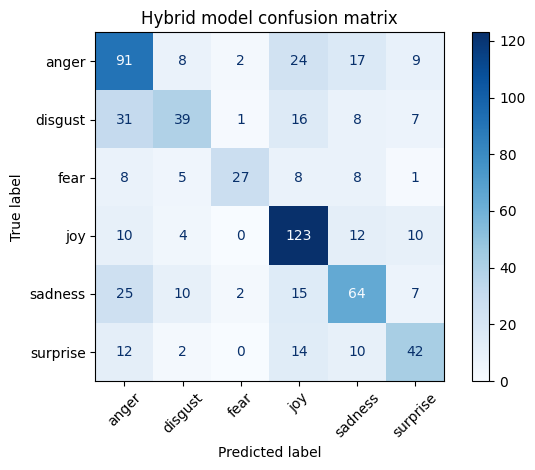

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

best_hybrid_model = hybrid_models[(1.0, 0.1)]

X_val_best = hstack([
    X_val_tfidf,
    csr_matrix(X_val_emb)
]).tocsr()

val_predictions = best_hybrid_model.predict(X_val_best)

print(classification_report(y_val, val_predictions))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_predictions,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Hybrid model confusion matrix")
plt.tight_layout()
plt.show()

Combining the features improved the macro F1 to 0.5622.
All six emotion classes improved compared to the tuned
TF-IDF model. Joy was the easiest class to predict, while disgust was the most difficult. Fear had high precision but relatively low recall.

In [13]:
# fitted TF-IDF on the full training dataset
final_tfidf = FeatureUnion([
    ("word", word_features()),
    ("char", char_features())
])

X_full_tfidf = final_tfidf.fit_transform(train["clean"])
X_test_tfidf = final_tfidf.transform(test["clean"])

# generate semantic embeddings
X_full_emb = encoder.encode(
    train["clean"].tolist(),
    normalize_embeddings=True,
    show_progress_bar=True
)

X_test_emb = encoder.encode(
    test["clean"].tolist(),
    normalize_embeddings=True,
    show_progress_bar=True
)

# combined lexical and semantic features
X_full_hybrid = hstack([
    X_full_tfidf,
    csr_matrix(X_full_emb)
]).tocsr()

X_test_hybrid = hstack([
    X_test_tfidf,
    csr_matrix(X_test_emb)
]).tocsr()

# trained the final classifier
final_model = LinearSVC(C=0.1, random_state=SEED)
final_model.fit(X_full_hybrid, train["label"])

test_predictions = final_model.predict(X_test_hybrid)

# created submission in the original sample order
prediction_df = pd.DataFrame({
    "post_id": test["post_id"].values,
    "label": test_predictions
})

submission = sample_submission[["post_id"]].merge(
    prediction_df,
    on="post_id",
    how="left",
    validate="one_to_one"
)

# validated submission
assert submission.shape == (1440, 2)
assert submission["label"].notna().all()
assert submission["post_id"].is_unique
assert submission.columns.tolist() == sample_submission.columns.tolist()
assert set(submission["label"]).issubset(set(train["label"]))

submission.to_csv(
    "/kaggle/working/submission.csv",
    index=False
)

display(submission.head())
print("Submission shape:", submission.shape)
print("\nPredicted class distribution:")
print(submission["label"].value_counts())

Batches:   0%|          | 0/105 [00:00<?, ?it/s]

Batches:   0%|          | 0/45 [00:00<?, ?it/s]

,post_id,label
0,xyzx9jp,anger
1,l3vzzxt,joy
2,g680iug,sadness
3,m4t8bp6,joy
4,ai3al6e,surprise


Submission shape: (1440, 2)

Predicted class distribution:
label
joy         478
anger       354
sadness     261
surprise    142
disgust     120
fear         85
Name: count, dtype: int64


In [3]:
import pandas as pd
import numpy as np
import json
import re
import torch
from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, accuracy_score, classification_report

SEED = 42

DATA_DIR = Path(
    "/kaggle/input/competitions/2026-dm-lab-2-private-competition"
)

# Load data
with open(DATA_DIR / "final_posts.json", encoding="utf-8") as f:
    raw_posts = json.load(f)

emotions = pd.read_csv(DATA_DIR / "emotion.csv")
identification = pd.read_csv(DATA_DIR / "data_identification.csv")
sample_submission = pd.read_csv(DATA_DIR / "sampleSubmission.csv")

# Merge datasets
posts = pd.DataFrame(raw_posts)

df = posts.merge(identification, on="post_id", validate="one_to_one")
df = df.merge(emotions, on="post_id", how="left", validate="one_to_one")

train = df[df["set"] == "train"].copy()
test = df[df["set"] == "test"].copy()

# Clean text
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " URL ", text)
    text = re.sub(r"@\w+", " USER ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

train["clean"] = train["text"].fillna("").apply(clean_text)
test["clean"] = test["text"].fillna("").apply(clean_text)

# Restore the same validation split
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

train_idx, val_idx = next(
    splitter.split(train["clean"], train["label"], groups=train["clean"])
)

X_train = train.iloc[train_idx]["clean"]
X_val = train.iloc[val_idx]["clean"]
y_train = train.iloc[train_idx]["label"]
y_val = train.iloc[val_idx]["label"]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Shared texts:", len(set(X_train) & set(X_val)))
print("GPU available:", torch.cuda.is_available())

Training samples: 2688
Validation samples: 672
Shared texts: 0
GPU available: True


## 3. Transformer models

### 3.1 RoBERTa

Although combining lexical and semantic features improved
the results, I wanted to see whether fine-tuning a transformer
directly on the classification task would perform better.

I kept the same validation split to make the results comparable. For the transformers, I used the original text instead of the cleaned version.

In [4]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding
)
from datasets import Dataset
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
label_encoder.fit(train["label"])
MODEL_NAME = "FacebookAI/roberta-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# used original text because capitalization and punctuation
# can provide additional emotional information
def prepare_dataset(indices):
    subset = train.iloc[indices]

    dataset = Dataset.from_dict({
        "text": subset["text"].fillna("").tolist(),
        "labels": label_encoder.transform(
            subset["label"]
        ).tolist()
    })

    return dataset.map(
        lambda batch: tokenizer(
            batch["text"],
            truncation=True,
            max_length=128
        ),
        batched=True,
        remove_columns=["text"]
    )

train_dataset = prepare_dataset(train_idx)
val_dataset = prepare_dataset(val_idx)
print(train_dataset)
print(val_dataset)
print(label_encoder.classes_)

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Map:   0%|          | 0/2688 [00:00<?, ? examples/s]

Map:   0%|          | 0/672 [00:00<?, ? examples/s]

Dataset({
    features: ['labels', 'input_ids', 'attention_mask'],
    num_rows: 2688
})
Dataset({
    features: ['labels', 'input_ids', 'attention_mask'],
    num_rows: 672
})
['anger' 'disgust' 'fear' 'joy' 'sadness' 'surprise']


In [6]:
from transformers import set_seed

set_seed(SEED)
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels, predictions, average="macro"
        )
    }
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=6
)
training_args = TrainingArguments(
    output_dir="/kaggle/working/roberta_emotions",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=4,
    weight_decay=0.01,
    warmup_steps=68,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,
    fp16=True,
    report_to="none",
    seed=SEED
)
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics
)
trainer.train()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and re

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,No log,2.864279,0.453869,0.278808
2,No log,2.416777,0.578869,0.554397
3,No log,2.323359,0.607143,0.594115
4,No log,2.365761,0.601190,0.591971


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=336, training_loss=2.319322313581194, metrics={'train_runtime': 124.8539, 'train_samples_per_second': 86.117, 'train_steps_per_second': 2.691, 'total_flos': 432158984155008.0, 'train_loss': 2.319322313581194, 'epoch': 4.0})

RoBERTa improved the macro F1 to 0.5941. The best result
was achieved after three epochs. After the fourth epoch,
the validation loss increased and the F1 score slightly decreased, which might indicate overfitting.

In [7]:
results = trainer.evaluate()
print(results)
print("Best checkpoint:", trainer.state.best_model_checkpoint)
roberta_output = trainer.predict(val_dataset)
roberta_logits = roberta_output.predictions
roberta_predictions = label_encoder.inverse_transform(
    np.argmax(roberta_logits, axis=-1)
)
print(classification_report(y_val, roberta_predictions))

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
No log,2.323359,4,0.607143,0.594115


{'eval_loss': 2.323359489440918, 'eval_accuracy': 0.6071428571428571, 'eval_macro_f1': 0.5941150803506182}
Best checkpoint: /kaggle/working/roberta_emotions/checkpoint-252


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


              precision    recall  f1-score   support

       anger       0.58      0.54      0.56       151
     disgust       0.51      0.44      0.47       102
        fear       0.79      0.53      0.63        57
         joy       0.68      0.80      0.73       159
     sadness       0.57      0.66      0.61       123
    surprise       0.57      0.54      0.55        80

    accuracy                           0.61       672
   macro avg       0.62      0.58      0.59       672
weighted avg       0.61      0.61      0.60       672



### 3.2 DeBERTa

Based on the improvement obtained with RoBERTa, I decided
to try another transformer architecture. I fine-tuned
DeBERTa for five epochs and selected the checkpoint based
on validation macro F1.

In [8]:
roberta_trainer = trainer
roberta_tokenizer = tokenizer
roberta_f1 = f1_score(
    y_val, roberta_predictions, average="macro"
)
MODEL_NAME = "microsoft/deberta-v3-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
train_dataset = prepare_dataset(train_idx)
val_dataset = prepare_dataset(val_idx)

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

Map:   0%|          | 0/2688 [00:00<?, ? examples/s]

Map:   0%|          | 0/672 [00:00<?, ? examples/s]

In [14]:
import gc
from transformers import EarlyStoppingCallback

set_seed(SEED)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=6
).float()

print("Model dtype:", next(model.parameters()).dtype)

training_args = TrainingArguments(
    output_dir="/kaggle/working/deberta",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    num_train_epochs=5,
    weight_decay=0.01,
    warmup_steps=50,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,
    logging_steps=20,
    fp16=True,
    report_to="none",
    seed=SEED
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics
)

trainer.train()

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
classifier

Model dtype: torch.float32


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,3.031396,2.822380,0.462798,0.300238
2,2.282359,2.402793,0.569940,0.508565
3,1.926717,2.333855,0.601190,0.589155
4,1.255271,2.477362,0.620536,0.613052
5,0.887891,2.679796,0.605655,0.585818
6,0.606310,2.931926,0.610119,0.596282


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (7 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1008, training_loss=1.735177669260237, metrics={'train_runtime': 353.2426, 'train_samples_per_second': 45.657, 'train_steps_per_second': 2.854, 'total_flos': 506951856242496.0, 'train_loss': 1.735177669260237, 'epoch': 6.0})

DeBERTa achieved a macro F1 of 0.6140 and outperformed
all previous models. However, disgust remained the most
difficult emotion to classify.

In [11]:
deberta_trainer = trainer
deberta_tokenizer = tokenizer
deberta_output = trainer.predict(val_dataset)
deberta_logits = deberta_output.predictions
deberta_predictions = label_encoder.inverse_transform(
    np.argmax(deberta_logits, axis=-1)
)
print(classification_report(y_val, deberta_predictions))

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


              precision    recall  f1-score   support

       anger       0.62      0.58      0.60       151
     disgust       0.48      0.46      0.47       102
        fear       0.74      0.56      0.64        57
         joy       0.77      0.77      0.77       159
     sadness       0.58      0.67      0.62       123
    surprise       0.54      0.61      0.58        80

    accuracy                           0.63       672
   macro avg       0.62      0.61      0.61       672
weighted avg       0.63      0.63      0.63       672



### 3.3 Model ensembling

I tested whether combining the probabilities of RoBERTa
and DeBERTa could improve the results. Although the models made different errors on 99 validation samples, the ensemble did not outperform DeBERTa alone. Therefore, I decided not to use this ensemble.

In [12]:
from scipy.special import softmax

roberta_probs = softmax(roberta_logits, axis=1)
deberta_probs = softmax(deberta_logits, axis=1)

ensemble_results = []

for weight in np.linspace(0, 1, 11):

    ensemble_probs = (
        weight * deberta_probs
        + (1 - weight) * roberta_probs
    )

    predictions = label_encoder.inverse_transform(
        np.argmax(ensemble_probs, axis=1)
    )

    ensemble_results.append({
        "DeBERTa weight": weight,
        "RoBERTa weight": 1 - weight,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro F1": f1_score(
            y_val, predictions, average="macro"
        )
    })

ensemble_df = pd.DataFrame(ensemble_results).sort_values(
    "Macro F1", ascending=False
)

display(ensemble_df.round(4))

,DeBERTa weight,RoBERTa weight,Accuracy,Macro F1
10,1.0,0.0,0.6265,0.6140
6,0.6,0.4,0.6280,0.6134
9,0.9,0.1,0.6250,0.6132
7,0.7,0.3,0.6265,0.6129
8,0.8,0.2,0.6235,0.6106
5,0.5,0.5,0.6220,0.6087
4,0.4,0.6,0.6220,0.6041
3,0.3,0.7,0.6161,0.5988
1,0.1,0.9,0.6116,0.5978
2,0.2,0.8,0.6131,0.5963


In [13]:
roberta_correct = roberta_predictions == y_val.to_numpy()
deberta_correct = deberta_predictions == y_val.to_numpy()

print("Both correct:", np.sum(roberta_correct & deberta_correct))
print("Only RoBERTa correct:", np.sum(roberta_correct & ~deberta_correct))
print("Only DeBERTa correct:", np.sum(deberta_correct & ~roberta_correct))
print("Both incorrect:", np.sum(~roberta_correct & ~deberta_correct))

Both correct: 365
Only RoBERTa correct: 43
Only DeBERTa correct: 56
Both incorrect: 208


### 3.4 Extended training

Since DeBERTa's F1 was still increasing after five epochs,
I wanted to check whether longer training could improve
the results. However, the best macro F1 was 0.6131, and early stoppingterminated training after six epochs. Therefore, I kept the original five-epoch configuration.

In [17]:
import gc

for name in [
    "trainer", "model", "roberta_trainer",
    "deberta_trainer", "emotion_classifier"
]:
    globals().pop(name, None)

gc.collect()
torch.cuda.empty_cache()

MODEL_NAME = "microsoft/deberta-v3-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# prepared all labeled samples and the test set
full_dataset = Dataset.from_dict({
    "text": train["text"].fillna("").tolist(),
    "labels": label_encoder.transform(train["label"]).tolist()
})

test_dataset = Dataset.from_dict({
    "text": test["text"].fillna("").tolist()
})

def tokenize_batch(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=128
    )

full_dataset = full_dataset.map(
    tokenize_batch,
    batched=True,
    remove_columns=["text"]
)

test_dataset = test_dataset.map(
    tokenize_batch,
    batched=True,
    remove_columns=["text"]
)

# initialized the final model
set_seed(SEED)

final_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=6
).float()

final_args = TrainingArguments(
    output_dir="/kaggle/working/deberta_final",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    num_train_epochs=5,
    weight_decay=0.01,
    warmup_steps=63,
    save_strategy="no",
    logging_steps=20,
    fp16=True,
    report_to="none",
    seed=SEED
)

final_trainer = Trainer(
    model=final_model,
    args=final_args,
    train_dataset=full_dataset,
    data_collator=DataCollatorWithPadding(tokenizer)
)

final_trainer.train()

Map:   0%|          | 0/3360 [00:00<?, ? examples/s]

Map:   0%|          | 0/1440 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
classifier

Step,Training Loss
20,3.577905
40,3.490817
60,3.482978
80,3.371198
100,3.384771
120,3.158464
140,2.955764
160,2.752202
180,2.810119
200,2.746324


TrainOutput(global_step=1050, training_loss=1.8544016956147693, metrics={'train_runtime': 328.1878, 'train_samples_per_second': 51.19, 'train_steps_per_second': 3.199, 'total_flos': 529111933652736.0, 'train_loss': 1.8544016956147693, 'epoch': 5.0})

In [18]:
# predicted the emotion of each test sample
test_output = final_trainer.predict(test_dataset)

test_predictions = label_encoder.inverse_transform(
    np.argmax(test_output.predictions, axis=1)
)

prediction_df = pd.DataFrame({
    "post_id": test["post_id"].values,
    "label": test_predictions
})

# matched the sample submission format and order
submission = sample_submission[["post_id"]].merge(
    prediction_df,
    on="post_id",
    how="left",
    validate="one_to_one"
)

assert submission.shape == (1440, 2)
assert submission["label"].notna().all()
assert submission["post_id"].is_unique
assert submission.columns.tolist() == sample_submission.columns.tolist()

submission.to_csv(
    "/kaggle/working/submission.csv",
    index=False
)

display(submission.head())
print(submission["label"].value_counts())

,post_id,label
0,xyzx9jp,surprise
1,l3vzzxt,anger
2,g680iug,sadness
3,m4t8bp6,joy
4,ai3al6e,surprise


label
joy         401
anger       319
sadness     269
surprise    179
disgust     169
fear        103
Name: count, dtype: int64
